In [ ]:
"""В данном модуле представлено сравнение точной и приближенной моделей
по методу Бартлетта для оценки азимута прихода сигнала
"""

%load_ext autoreload
%autoreload 2

import numpy as np
import time
import src.experement as experement
import src.pseudospectrum as pseudospectrum
import src.configs.config as config
import src.signals as signals
import src.model as model
import src.plotting as plotting
import os

origin_config = config.init_rng()
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)

config_random = dict( # noqa: C408
                    is_CRN = False, 
                    is_random_start = False)

config_bartlett_aprox = dict(  # noqa: C408
                            energy_func=pseudospectrum.approx_bartlett,
                            signal_func = signals.sinus,
                            stiring_func = model.calculate_stiring_matrix,
                            **config_random)
config_bartlett_exact  = dict(  # noqa: C408
                            energy_func = pseudospectrum.exact_bartlett,
                            signal_func = signals.sinus,
                            stiring_func = model.complex_stiring_matrix,
                            **config_random)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config_parametrs1
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = origin_config['phi_values'],
) 

var_bartlett_vs_phis = experement.stat_vs_params(config_params=config_parametrs1,
                                     stat_func = experement.calculate_variance,
                                   **config_bartlett_aprox,
                                   **parametr_config)
var_bartlett_vs_phis_complex = experement.stat_vs_params(config_params = config_parametrs2,
                                             stat_func = experement.calculate_variance,
                                             **config_bartlett_exact,
                                             **parametr_config)

config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_phis) - np.array(var_bartlett_vs_phis_complex))
mean_bartlett_vs_phis = experement.stat_vs_params(config_params=config_parametrs1,
                                   stat_func = np.mean,
                                   **config_bartlett_aprox,
                                   **parametr_config
                                   )

mean_bartlett_vs_phis_complex = experement.stat_vs_params(config_params = config_parametrs2,
                                              stat_func = np.mean,
                                             **config_bartlett_exact,
                                             **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlett_vs_phis) - np.array(mean_bartlett_vs_phis_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Source azimuth $\\varphi_0$, deg', ylabel='$\\mathbb{E}[\\varepsilon]$, deg'>)

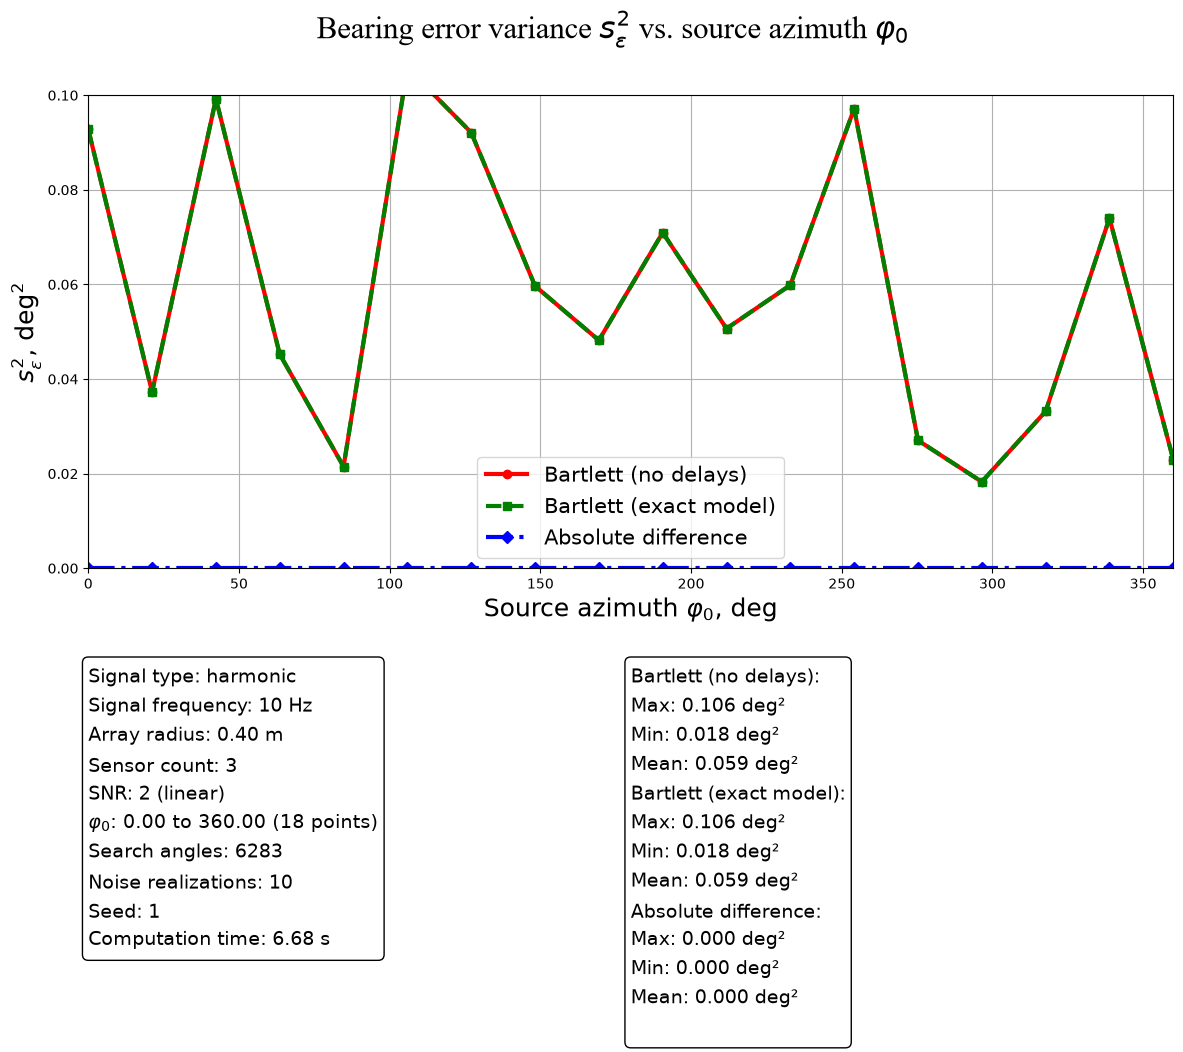

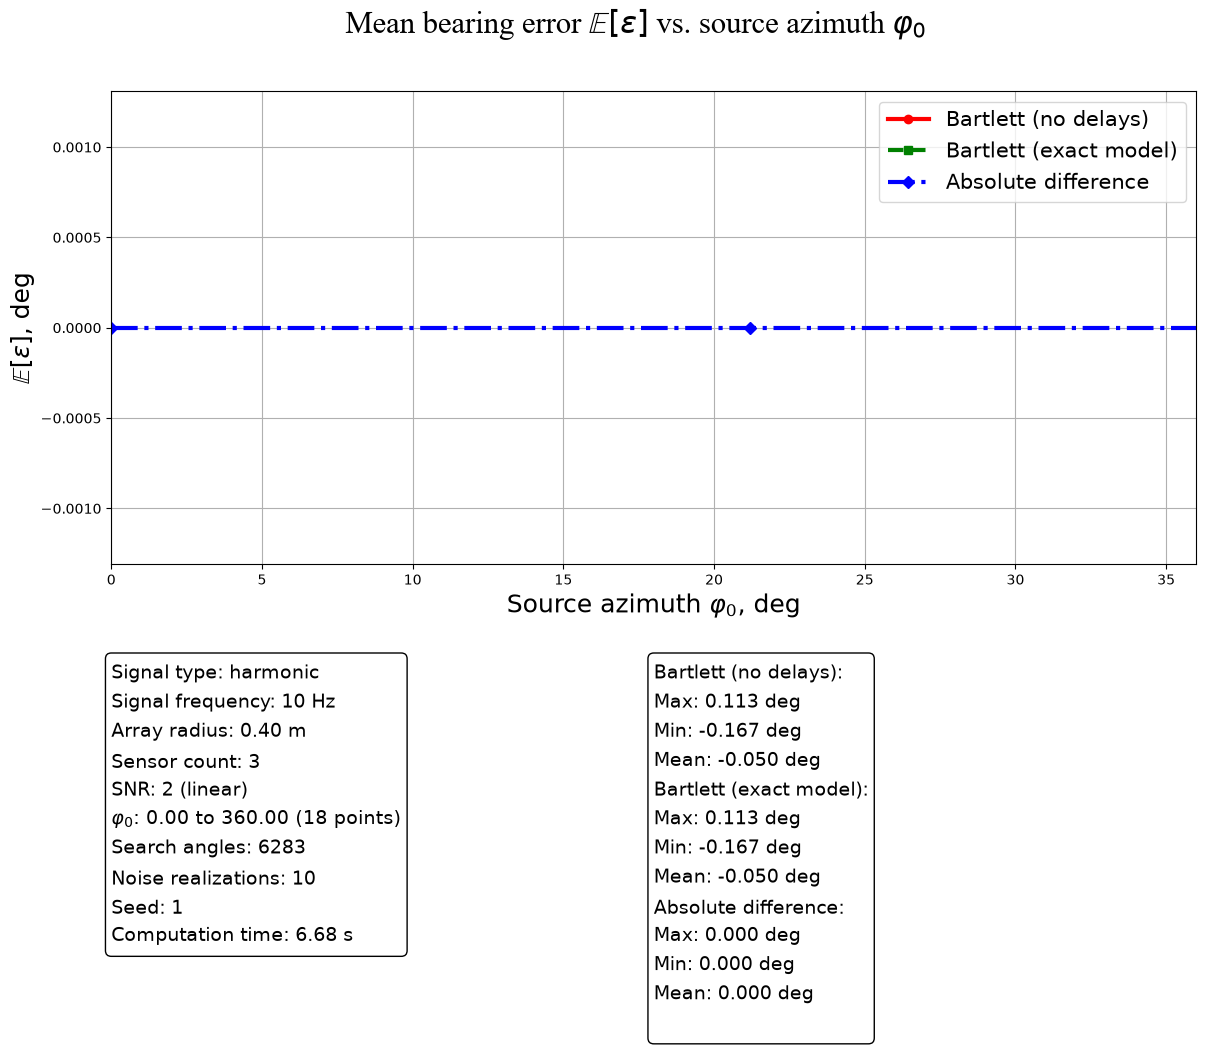

In [28]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett (no delays)": var_bartlett_vs_phis,
                                      "Bartlett (exact model)": var_bartlett_vs_phis_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*origin_config['const_radian'], 0.1*origin_config['const_radian']),
                       xlim = (0,360),
                       type_signal = "garmonic",
                       **parametr_config)
plotting.plot_mean_vs_param(dict_values = {"Bartlett (no delays)": mean_bartlett_vs_phis,
                                  "Bartlett (exact model)": mean_bartlett_vs_phis_complex,
                                  "Absolute difference": mean_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (-0.075*origin_config['const_radian'], 0.075*origin_config['const_radian']),
                       xlim = (0,36),
                       type_signal = "garmonic",
                       **parametr_config)

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "snr",
    parametr_values = origin_config['snr_values'],
) 
var_bartlett_vs_snr = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = experement.calculate_variance,
                                    **config_bartlett_aprox,
                                    **parametr_config)
var_bartlett_vs_snr_complex = experement.stat_vs_params(config_params = config_parametrs2,
                                   stat_func = experement.calculate_variance,
                                   **config_bartlett_exact,
                                   **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_snr) - np.array(var_bartlett_vs_snr_complex))
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
mean_bartlett_vs_snr = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_aprox,
                                    **parametr_config)
mean_bartlett_vs_snr_complex = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_exact,
                                    **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlett_vs_snr) - np.array(mean_bartlett_vs_snr_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='SNR (linear)', ylabel='$\\mathbb{E}[\\varepsilon]$, deg'>)

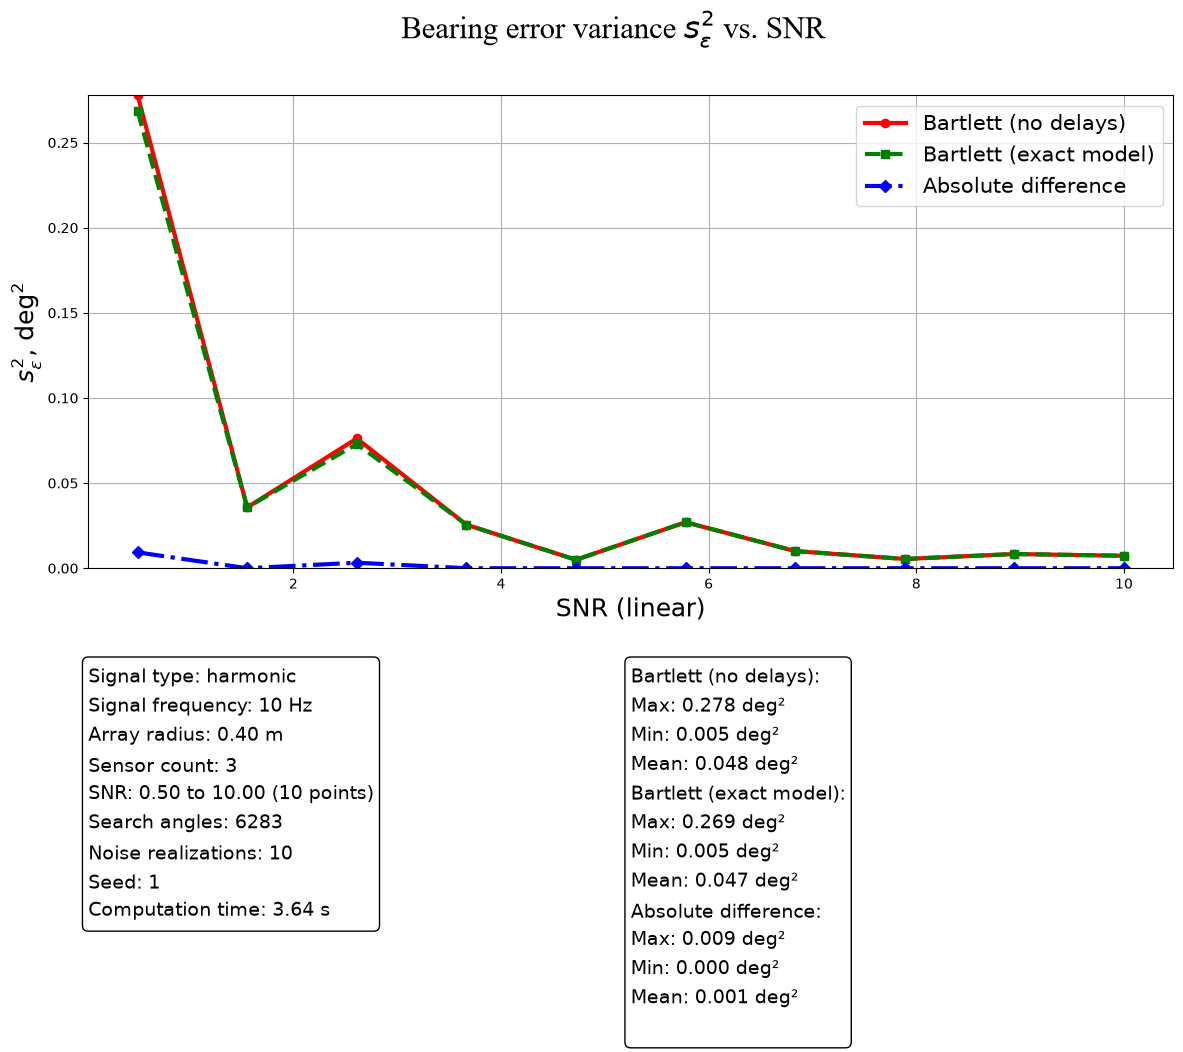

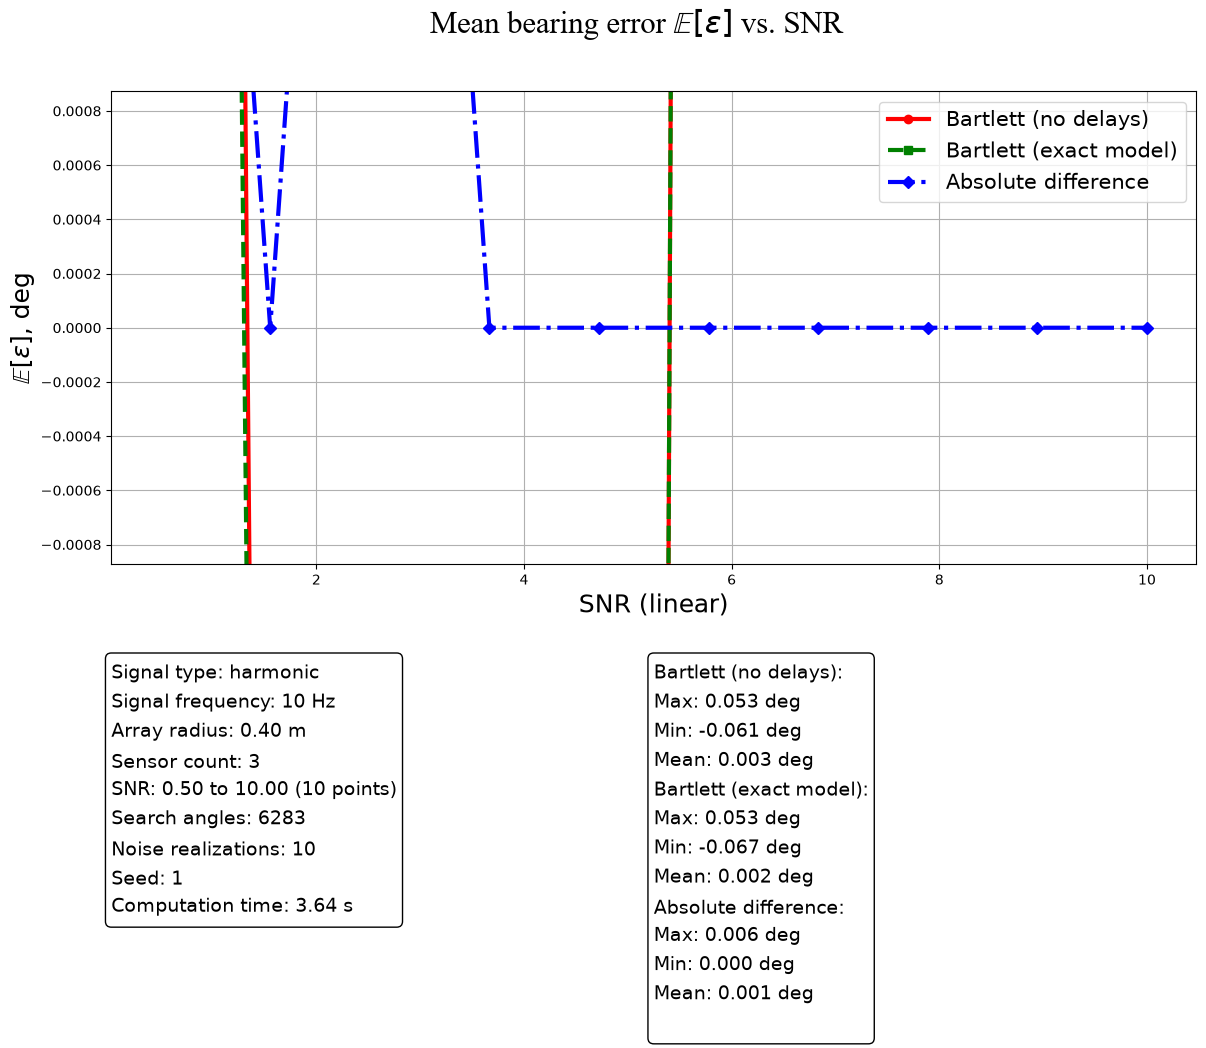

In [30]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett (no delays)": var_bartlett_vs_snr,
                                      "Bartlett (exact model)": var_bartlett_vs_snr_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, max(max(var_bartlett_vs_snr),max(var_bartlett_vs_snr_complex))),
                       type_signal = "garmonic",
                       **parametr_config)

plotting.plot_mean_vs_param(dict_values = {"Bartlett (no delays)": mean_bartlett_vs_snr,
                                 "Bartlett (exact model)": mean_bartlett_vs_snr_complex,
                                 "Absolute difference": mean_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (-0.05*origin_config['const_radian'], 0.05*origin_config['const_radian']),
                       type_signal = "garmonic",
                       **parametr_config)

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "R",
    parametr_values = origin_config['radius_values'],
) 
var_bartlett_vs_r = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = experement.calculate_variance,
                                    **config_bartlett_aprox,
                                    **parametr_config)
var_bartlett_vs_r_complex = experement.stat_vs_params(config_params = config_parametrs2,
                                   stat_func = experement.calculate_variance,
                                   **config_bartlett_exact,
                                   **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_r) - np.array(var_bartlett_vs_r_complex))
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
mean_bartlett_vs_r = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_aprox,
                                    **parametr_config)
mean_bartlett_vs_r_complex = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_exact,
                                    **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlett_vs_r) - np.array(mean_bartlett_vs_r_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Array radius $R$, m', ylabel='$\\mathbb{E}[\\varepsilon]$, deg'>)

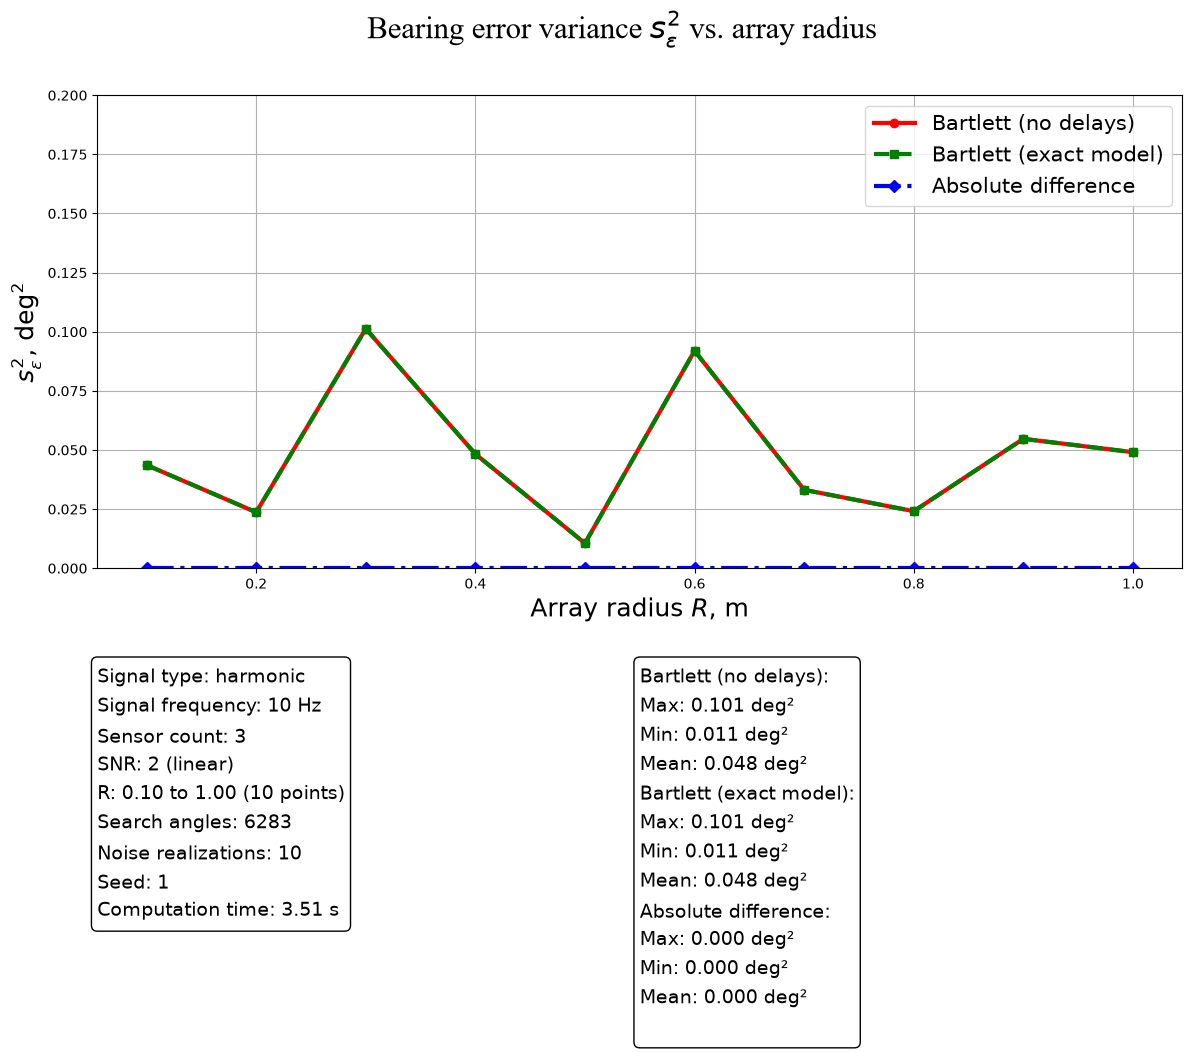

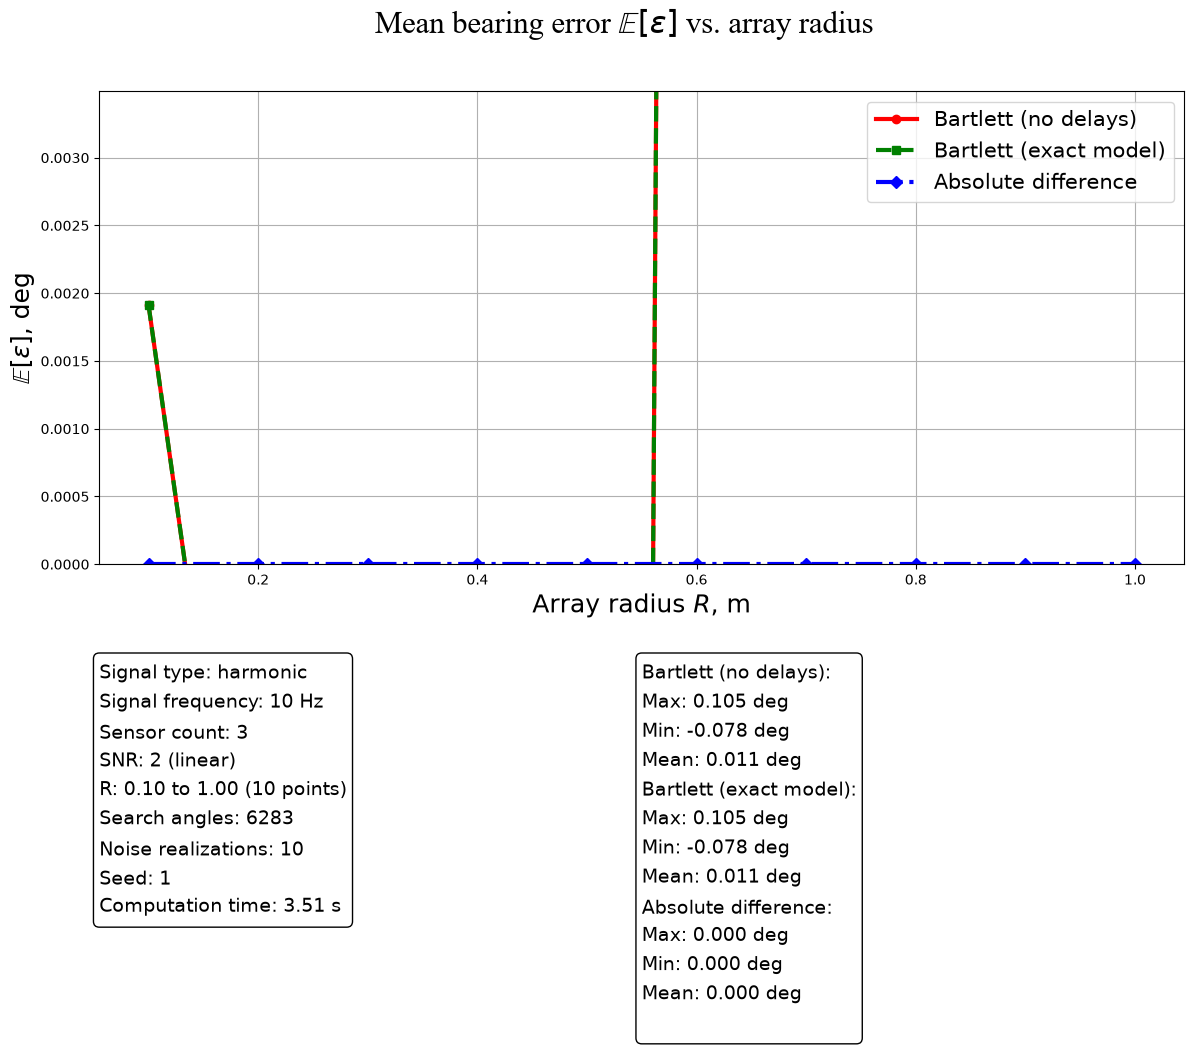

In [32]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett (no delays)": var_bartlett_vs_r,
                                      "Bartlett (exact model)": var_bartlett_vs_r_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.2*origin_config['const_radian']),
                       type_signal = "garmonic",
                       **parametr_config
                       )
plotting.plot_mean_vs_param(dict_values = {"Bartlett (no delays)": mean_bartlett_vs_r,
                                  "Bartlett (exact model)": mean_bartlett_vs_r_complex,
                                  "Absolute difference": mean_delta_abs},
                                  config_params = origin_config.copy(),
                                  delta_time = delta_time,
                                  ylim = (0, 0.2*origin_config['const_radian']),
                                  type_signal = "garmonic",
                                  **parametr_config)

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "M",
    parametr_values = origin_config['sensor_values'],
) 
var_bartlett_vs_m = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = experement.calculate_variance,
                                    **config_bartlett_aprox,
                                    **parametr_config)
var_bartlett_vs_m_complex = experement.stat_vs_params(config_params = config_parametrs2,
                                   stat_func = experement.calculate_variance,
                                   **config_bartlett_exact,
                                   **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_m) - np.array(var_bartlett_vs_m_complex))
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
mean_bartlett_vs_m = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_aprox,
                                    **parametr_config)
mean_bartlett_vs_m_complex = experement.stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_exact,
                                    **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlett_vs_m) - np.array(mean_bartlett_vs_m_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Sensor count $M$', ylabel='$\\mathbb{E}[\\varepsilon]$, deg'>)

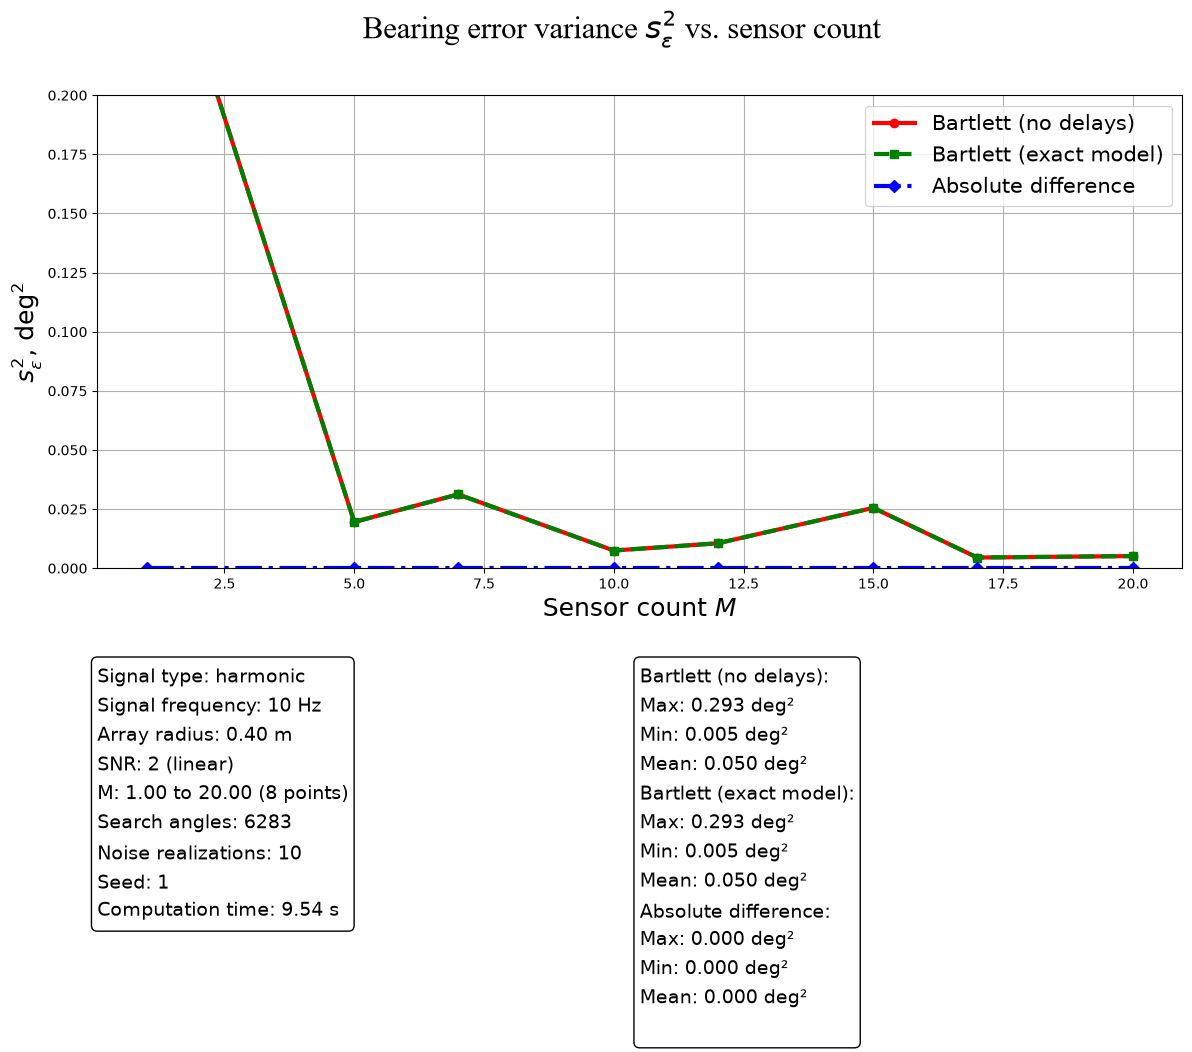

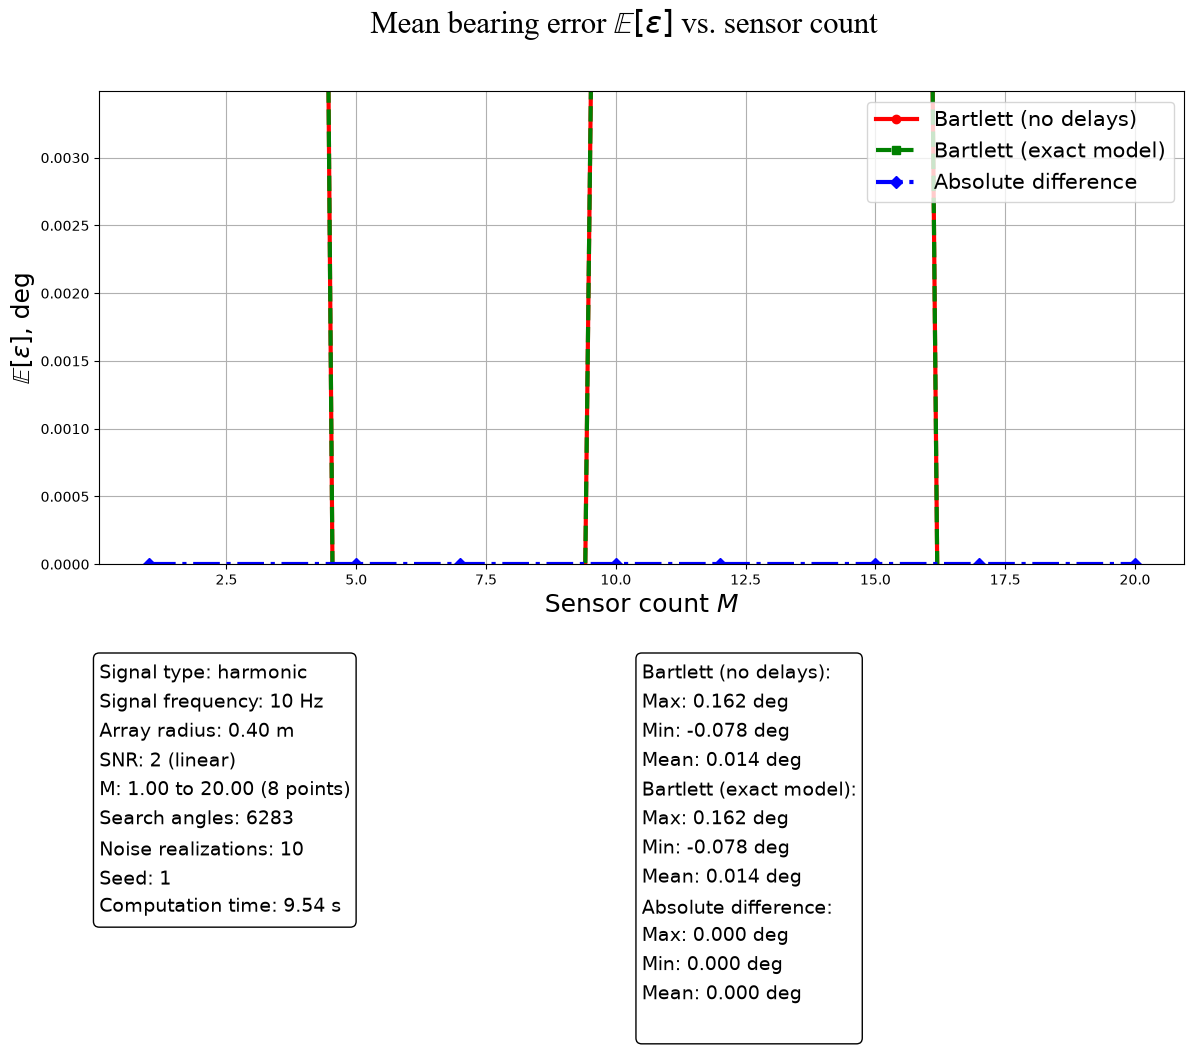

In [34]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett (no delays)": var_bartlett_vs_m,
                                      "Bartlett (exact model)": var_bartlett_vs_m_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.2*origin_config['const_radian']),
                       type_signal = "garmonic",
                       **parametr_config )
plotting.plot_mean_vs_param(dict_values = {"Bartlett (no delays)": mean_bartlett_vs_m,
                                  "Bartlett (exact model)": mean_bartlett_vs_m_complex,
                                  "Absolute difference": mean_delta_abs},
                                  config_params = origin_config.copy(),
                                  delta_time = delta_time,
                                  ylim = (0, 0.2*origin_config['const_radian']),
                                  type_signal = "garmonic",
                                  **parametr_config)